# 03 — Feature Engineering and Feature Selection

## Task 2: multiclass classification — synthetic sleep profiles

This notebook develops a feature-engineering and feature-selection workflow for a **four-class classification problem**.

The central difference from binary classification is that a predictor can distinguish one class from the others, separate several classes, or vary in different directions across groups. Feature selection should therefore use **multiclass-aware** statistics and models rather than reducing the problem to an arbitrary sequence of binary tests.

## Learning objectives

After completing this notebook, students should be able to:

- engineer interpretable sleep-related features without using the class label;
- preserve a held-out test partition before supervised selection;
- inspect redundancy introduced by engineered variables;
- use Kruskal–Wallis and effect sizes for numerical multiclass screening;
- use chi-square and Cramér's V for categorical multiclass screening;
- estimate multiclass mutual information;
- use L1-regularized multinomial logistic regression as an embedded selector;
- inspect class-specific coefficient patterns rather than only a global ranking;
- combine multiple forms of evidence into candidate feature sets.

## 1. Multiclass feature-selection principle

A multiclass selector should preserve the class structure of the task.

For example, a variable can be highly informative because only `sleep_apnea` differs, while the other three classes overlap. An omnibus statistic can detect this without forcing a binary interpretation.

As in Task 1, every target-dependent decision is learned on the **training partition only**.

## 2. Imports and reproducibility

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.multitest import multipletests

from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.linear_model import LogisticRegression, ElasticNetCV
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
PASTEL_SEQUENTIAL_CMAP = sns.light_palette("#5B8DB8", as_cmap=True)
PASTEL_DIVERGING_CMAP = sns.diverging_palette(275, 145, s=45, l=75, center="light", as_cmap=True)

## 3. Project paths

In [2]:
def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir() and (candidate / "notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the repository root. Run the notebook from inside the project."
    )

PROJECT_ROOT = find_project_root(Path.cwd())

PROCESSED_DIR = PROJECT_ROOT / "data" / "synthetic_sleep_profiles" / "processed_data"
PROCESSED_DATA_PATH = PROCESSED_DIR / "synthetic_sleep_profiles_1200_processed.csv"
PREPROCESSING_REPORT_PATH = PROCESSED_DIR / "preprocessing_report.json"

FEATURE_DATA_DIR = PROJECT_ROOT / "data" / "synthetic_sleep_profiles" / "feature_data"
RESULTS_DIR = PROJECT_ROOT / "results" / "synthetic_sleep_profiles" / "feature_engineering_selection"
FIGURES_DIR = RESULTS_DIR / "figures"
TABLES_DIR = RESULTS_DIR / "tables"

for directory in [FEATURE_DATA_DIR, FIGURES_DIR, TABLES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Results:", RESULTS_DIR.relative_to(PROJECT_ROOT))

Project root: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
Results: results/synthetic_sleep_profiles/feature_engineering_selection


## 4. Load the processed dataset and analytical roles

In [3]:
if not PROCESSED_DATA_PATH.exists() or not PREPROCESSING_REPORT_PATH.exists():
    raise FileNotFoundError(
        "Processed data are missing. Run task2_sleep_profiles/01_tabular_data_preprocessing.ipynb first."
    )

df = pd.read_csv(PROCESSED_DATA_PATH)
with PREPROCESSING_REPORT_PATH.open("r", encoding="utf-8") as file:
    preprocessing_report = json.load(file)

ID_COLUMN = preprocessing_report["identifier_column"]
TARGET_COLUMN = preprocessing_report["target_column"]
TARGET_CLASSES = list(preprocessing_report["target_classes"])
ORIGINAL_NUMERICAL = list(preprocessing_report["numerical_columns"])
CATEGORICAL_COLUMNS = list(preprocessing_report["categorical_columns"])

print("Shape:", df.shape)
print("Classes:", TARGET_CLASSES)
display(df[TARGET_COLUMN].value_counts().reindex(TARGET_CLASSES).rename("n").to_frame())

Shape: (1200, 23)
Classes: ['healthy_sleep', 'insomnia', 'sleep_apnea', 'circadian_disruption']


,n
sleep_profile,
healthy_sleep,283
insomnia,291
sleep_apnea,298
circadian_disruption,328


## 5. Stratified train/test split

The split preserves the four-class composition. The test labels are not used to select features.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df[TARGET_COLUMN],
    random_state=RANDOM_STATE,
)

split_counts = pd.crosstab(
    pd.Series(["train"] * len(train_df) + ["test"] * len(test_df), name="partition"),
    pd.concat([train_df[TARGET_COLUMN], test_df[TARGET_COLUMN]], ignore_index=True),
)
display(split_counts)

split_assignments = pd.concat([
    train_df[[ID_COLUMN]].assign(split="train"),
    test_df[[ID_COLUMN]].assign(split="test"),
], ignore_index=True)
split_assignments.to_csv(TABLES_DIR / "train_test_split.csv", index=False)

sleep_profile,circadian_disruption,healthy_sleep,insomnia,sleep_apnea
partition,,,,
test,66,56,58,60
train,262,227,233,238


# Part I — Feature engineering

## 6. Construct interpretable sleep features

The engineered variables represent concepts that are not identical to any single original measurement:

- deviation from an 8-hour sleep duration;
- efficiency deficit;
- awakenings normalized by hours slept;
- a combined circadian-disruption index;
- a small behavioral risk count.

These formulas do not use `sleep_profile`.

In [5]:
def engineer_sleep_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()

    out["sleep_duration_deviation_8h"] = (out["sleep_duration_hours"] - 8.0).abs()
    out["sleep_efficiency_deficit_pct"] = 100.0 - out["sleep_efficiency_pct"]
    out["sleep_fragmentation_per_hour"] = (
        out["night_awakenings"] / out["sleep_duration_hours"].clip(lower=0.5)
    )
    out["circadian_disruption_index"] = (
        out["social_jetlag_hours"] + out["bedtime_variability_min"] / 60.0
    )
    out["behavioral_risk_count"] = (
        out["shift_worker"]
        + out["evening_alcohol"]
        + out["anxiety_history"]
        + (1 - out["regular_exercise"])
    )
    return out


train_eng = engineer_sleep_features(train_df)
test_eng = engineer_sleep_features(test_df)
full_eng = engineer_sleep_features(df)

ENGINEERED_NUMERICAL = [
    "sleep_duration_deviation_8h",
    "sleep_efficiency_deficit_pct",
    "sleep_fragmentation_per_hour",
    "circadian_disruption_index",
    "behavioral_risk_count",
]
NUMERICAL_COLUMNS = ORIGINAL_NUMERICAL + ENGINEERED_NUMERICAL
FEATURE_COLUMNS = NUMERICAL_COLUMNS + CATEGORICAL_COLUMNS

assert train_eng[FEATURE_COLUMNS].isna().sum().sum() == 0
assert np.isfinite(train_eng[FEATURE_COLUMNS].to_numpy(dtype=float)).all()

engineering_table = pd.DataFrame({
    "engineered_feature": ENGINEERED_NUMERICAL,
    "interpretation": [
        "Absolute deviation from 8 hours of sleep",
        "100 minus measured sleep efficiency",
        "Night awakenings normalized by sleep duration",
        "Social jetlag plus bedtime variability expressed in hours",
        "Count of shift work, evening alcohol, anxiety, and inactivity indicators",
    ],
})
display(engineering_table)

,engineered_feature,interpretation
0,sleep_duration_deviation_8h,Absolute deviation from 8 hours of sleep
1,sleep_efficiency_deficit_pct,100 minus measured sleep efficiency
2,sleep_fragmentation_per_hour,Night awakenings normalized by sleep duration
3,circadian_disruption_index,Social jetlag plus bedtime variability express...
4,behavioral_risk_count,"Count of shift work, evening alcohol, anxiety,..."


## 7. Export the engineered candidate dataset

In [6]:
ENGINEERED_DATA_PATH = FEATURE_DATA_DIR / "synthetic_sleep_profiles_engineered.csv"
full_eng.to_csv(ENGINEERED_DATA_PATH, index=False)
print("Exported:", ENGINEERED_DATA_PATH.relative_to(PROJECT_ROOT))
print("Shape:", full_eng.shape)

Exported: data/synthetic_sleep_profiles/feature_data/synthetic_sleep_profiles_engineered.csv
Shape: (1200, 28)


# Part II — Unsupervised screening

## 8. Constant, near-constant, and redundant features

These checks do not use class labels. They identify structural properties of the feature space before supervised ranking.

In [7]:
constant_numerical = [c for c in NUMERICAL_COLUMNS if train_eng[c].nunique(dropna=False) <= 1]

categorical_prevalence = train_eng[CATEGORICAL_COLUMNS].mean().rename("prevalence").to_frame()
categorical_prevalence["near_constant"] = (
    (categorical_prevalence["prevalence"] < 0.01)
    | (categorical_prevalence["prevalence"] > 0.99)
)

print("Constant numerical features:", constant_numerical or "None")
display(categorical_prevalence.sort_values("prevalence"))

Constant numerical features: None


,prevalence,near_constant
loud_snoring,0.051042,False
shift_worker,0.119792,False
anxiety_history,0.212500,False
evening_alcohol,0.226042,False
sex_female,0.526042,False
regular_exercise,0.612500,False


In [8]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    valid = np.isfinite(p_values)
    adjusted = np.full(len(p_values), np.nan, dtype=float)
    rejected = np.full(len(p_values), False, dtype=bool)
    if valid.any():
        rejected_valid, adjusted_valid, _, _ = multipletests(
            p_values[valid], alpha=0.05, method="fdr_bh"
        )
        adjusted[valid] = adjusted_valid
        rejected[valid] = rejected_valid
    return adjusted, rejected


def cramers_v(table):
    chi2, _, _, _ = stats.chi2_contingency(table, correction=False)
    n = table.to_numpy().sum()
    if n == 0:
        return np.nan
    r, k = table.shape
    denominator = min(k - 1, r - 1)
    if denominator <= 0:
        return 0.0
    return np.sqrt((chi2 / n) / denominator)


def hedges_g(x0, x1):
    x0 = np.asarray(x0, dtype=float)
    x1 = np.asarray(x1, dtype=float)
    x0 = x0[np.isfinite(x0)]
    x1 = x1[np.isfinite(x1)]
    n0, n1 = len(x0), len(x1)
    if n0 < 2 or n1 < 2:
        return np.nan
    pooled_var = ((n0 - 1) * x0.var(ddof=1) + (n1 - 1) * x1.var(ddof=1)) / (n0 + n1 - 2)
    if pooled_var <= 0:
        return 0.0
    d = (x1.mean() - x0.mean()) / np.sqrt(pooled_var)
    correction = 1 - 3 / (4 * (n0 + n1) - 9)
    return correction * d


def cliffs_delta_from_u(u_statistic, n0, n1):
    if n0 == 0 or n1 == 0:
        return np.nan
    return (2 * u_statistic) / (n0 * n1) - 1


def correlation_pairs(corr, threshold=0.90):
    rows = []
    columns = list(corr.columns)
    for i, left in enumerate(columns):
        for right in columns[i + 1:]:
            value = corr.loc[left, right]
            if np.isfinite(value) and abs(value) >= threshold:
                rows.append({
                    "feature_a": left,
                    "feature_b": right,
                    "spearman_rho": value,
                    "abs_spearman_rho": abs(value),
                })
    if not rows:
        return pd.DataFrame(columns=["feature_a", "feature_b", "spearman_rho", "abs_spearman_rho"])
    return pd.DataFrame(rows).sort_values("abs_spearman_rho", ascending=False).reset_index(drop=True)


def plot_horizontal_ranking(frame, value_col, label_col, title, xlabel, path, top_n=20):
    plot_df = frame.sort_values(value_col, ascending=False).head(top_n).copy()
    plt.figure(figsize=(9, max(4.5, 0.34 * len(plot_df))))
    sns.barplot(data=plot_df, y=label_col, x=value_col, color=sns.color_palette("pastel")[0])
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("")
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()

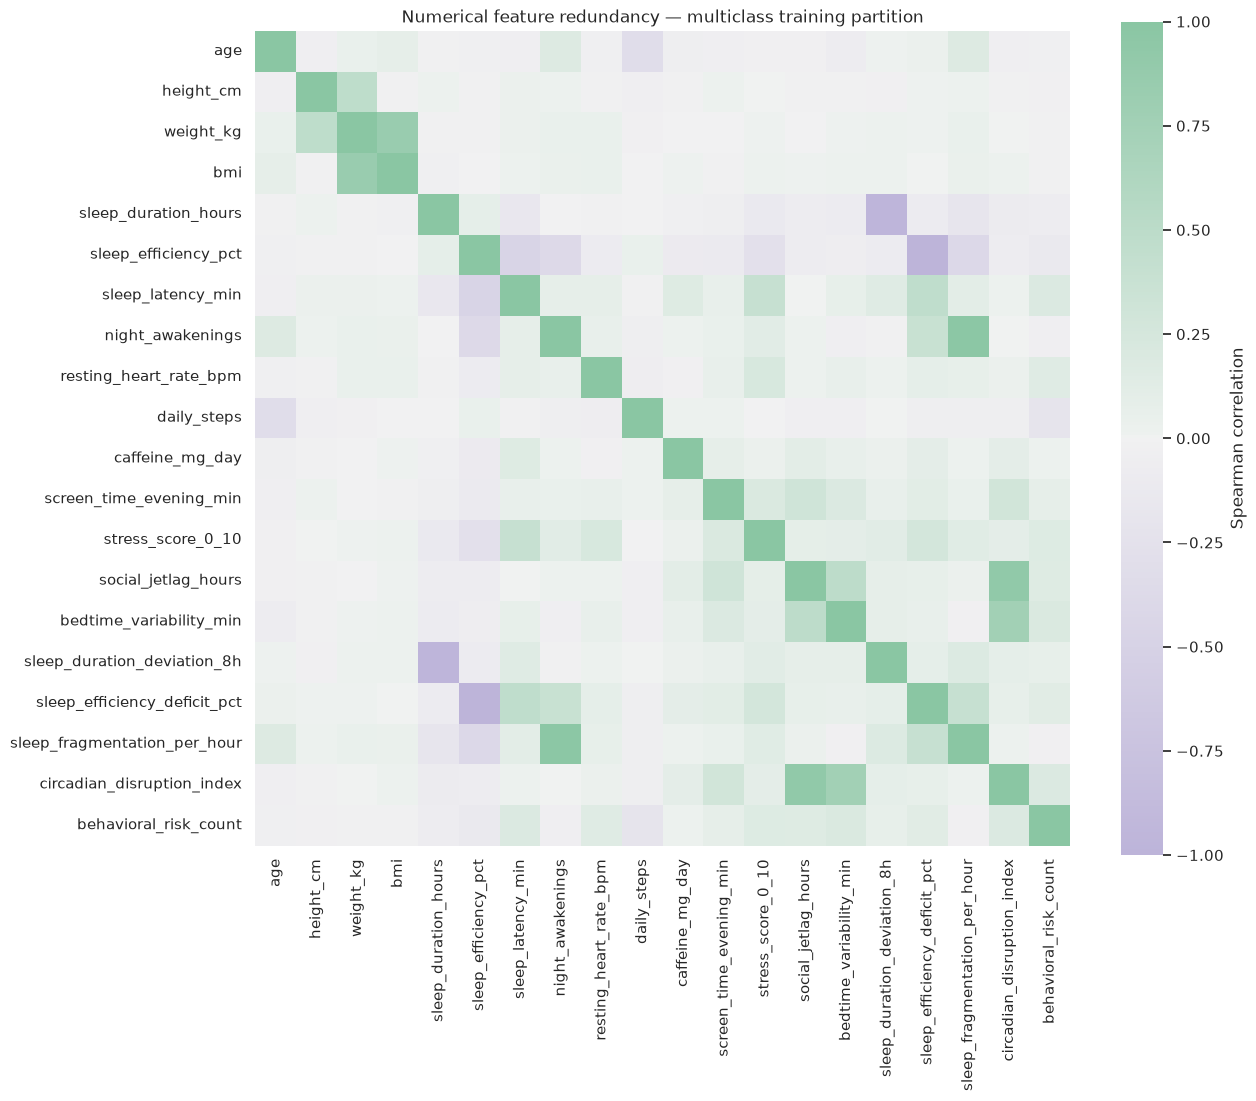

,feature_a,feature_b,spearman_rho,abs_spearman_rho
0,sleep_efficiency_pct,sleep_efficiency_deficit_pct,-1.000000,1.000000
1,night_awakenings,sleep_fragmentation_per_hour,0.973136,0.973136
2,sleep_duration_hours,sleep_duration_deviation_8h,-0.972113,0.972113
3,social_jetlag_hours,circadian_disruption_index,0.927731,0.927731


In [9]:
spearman_corr = train_eng[NUMERICAL_COLUMNS].corr(method="spearman")
redundant_pairs = correlation_pairs(spearman_corr, threshold=0.90)

plt.figure(figsize=(13, 11))
sns.heatmap(
    spearman_corr,
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={"label": "Spearman correlation"},
)
plt.title("Numerical feature redundancy — multiclass training partition")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_numerical_redundancy_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

display(redundant_pairs.head(20))
redundant_pairs.to_csv(TABLES_DIR / "numerical_redundant_pairs.csv", index=False)

# Part III — Multiclass filter methods

## 9. Numerical predictors: Kruskal–Wallis and epsilon-squared

Kruskal–Wallis is an omnibus rank-based test. A significant result means that at least one class distribution differs, but it does not tell us which pair differs.

We complement the p-value with **epsilon-squared**, an omnibus effect-size estimate. For this teaching example, `ε² >= 0.01` plus FDR significance is used as a permissive screening criterion.

,feature,kruskal_h,p_value,epsilon_squared,q_value,fdr_reject,filter_selected
0,sleep_latency_min,170.4577,0.0000,0.1752,0.0000,True,True
1,circadian_disruption_index,118.1001,0.0000,0.1204,0.0000,True,True
2,sleep_efficiency_pct,101.8399,0.0000,0.1034,0.0000,True,True
3,sleep_efficiency_deficit_pct,101.8399,0.0000,0.1034,0.0000,True,True
4,stress_score_0_10,100.2783,0.0000,0.1018,0.0000,True,True
5,bedtime_variability_min,95.6418,0.0000,0.0969,0.0000,True,True
6,social_jetlag_hours,92.8593,0.0000,0.0940,0.0000,True,True
7,age,37.4252,0.0000,0.0360,0.0000,True,True
8,screen_time_evening_min,36.2193,0.0000,0.0347,0.0000,True,True
9,sleep_fragmentation_per_hour,34.9574,0.0000,0.0334,0.0000,True,True


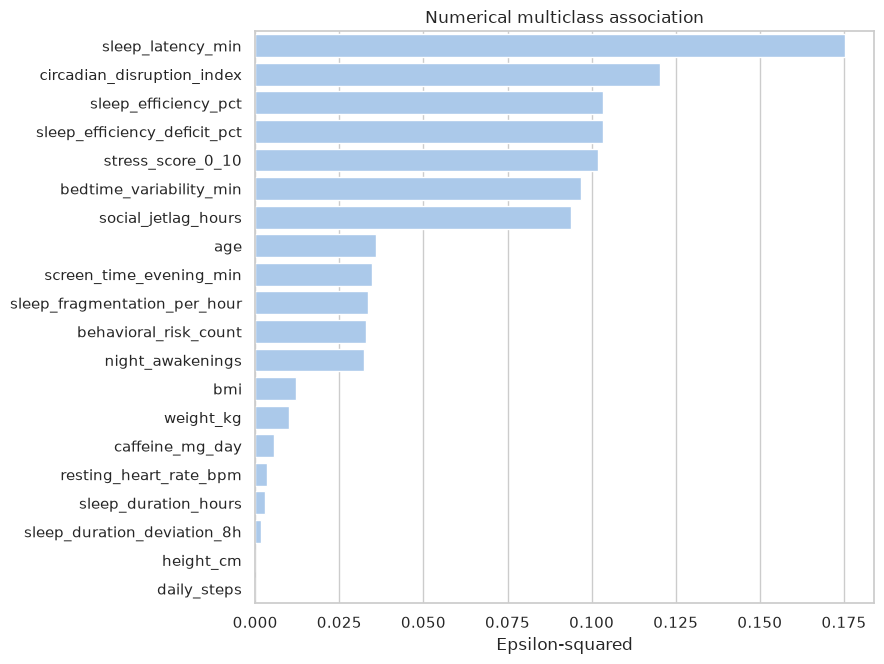

In [10]:
numerical_rows = []
for feature in NUMERICAL_COLUMNS:
    groups = [
        train_eng.loc[train_eng[TARGET_COLUMN] == cls, feature].dropna().to_numpy()
        for cls in TARGET_CLASSES
    ]
    result = stats.kruskal(*groups)
    n = sum(len(group) for group in groups)
    k = len(groups)
    epsilon_sq = max(0.0, (result.statistic - k + 1) / (n - k)) if n > k else np.nan

    numerical_rows.append({
        "feature": feature,
        "kruskal_h": result.statistic,
        "p_value": result.pvalue,
        "epsilon_squared": epsilon_sq,
    })

numerical_filter = pd.DataFrame(numerical_rows)
numerical_filter["q_value"], numerical_filter["fdr_reject"] = benjamini_hochberg(
    numerical_filter["p_value"]
)
numerical_filter["filter_selected"] = (
    numerical_filter["fdr_reject"]
    & (numerical_filter["epsilon_squared"] >= 0.01)
)
numerical_filter = numerical_filter.sort_values("epsilon_squared", ascending=False).reset_index(drop=True)

display(numerical_filter.round(4))
numerical_filter.to_csv(TABLES_DIR / "numerical_filter_selection.csv", index=False)
plot_horizontal_ranking(
    numerical_filter,
    "epsilon_squared",
    "feature",
    "Numerical multiclass association",
    "Epsilon-squared",
    FIGURES_DIR / "02_numerical_multiclass_effect_sizes.png",
)

## 10. Categorical predictors: chi-square and Cramér's V

Each binary predictor is compared with the full four-class label in one contingency table. This preserves the multiclass structure.

,feature,chi_square,p_value,cramers_v,q_value,fdr_reject,filter_selected
0,shift_worker,134.3626,0.0000,0.3741,0.0000,True,True
1,anxiety_history,23.6640,0.0000,0.1570,0.0001,True,True
2,loud_snoring,13.6045,0.0035,0.1190,0.0070,True,True
3,evening_alcohol,5.8146,0.1210,0.0778,0.1815,False,False
4,sex_female,3.9204,0.2702,0.0639,0.3242,False,False
5,regular_exercise,2.5901,0.4592,0.0519,0.4592,False,False


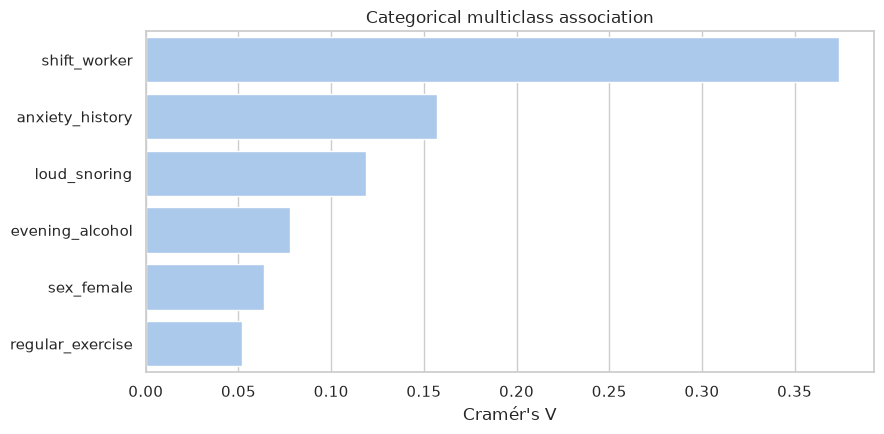

In [11]:
categorical_rows = []
for feature in CATEGORICAL_COLUMNS:
    table = pd.crosstab(train_eng[feature], train_eng[TARGET_COLUMN]).reindex(
        columns=TARGET_CLASSES, fill_value=0
    )
    chi2, p_value, _, _ = stats.chi2_contingency(table, correction=False)
    categorical_rows.append({
        "feature": feature,
        "chi_square": chi2,
        "p_value": p_value,
        "cramers_v": cramers_v(table),
    })

categorical_filter = pd.DataFrame(categorical_rows)
categorical_filter["q_value"], categorical_filter["fdr_reject"] = benjamini_hochberg(
    categorical_filter["p_value"]
)
categorical_filter["filter_selected"] = (
    categorical_filter["fdr_reject"]
    & (categorical_filter["cramers_v"] >= 0.10)
)
categorical_filter = categorical_filter.sort_values("cramers_v", ascending=False).reset_index(drop=True)

display(categorical_filter.round(4))
categorical_filter.to_csv(TABLES_DIR / "categorical_filter_selection.csv", index=False)
plot_horizontal_ranking(
    categorical_filter,
    "cramers_v",
    "feature",
    "Categorical multiclass association",
    "Cramér's V",
    FIGURES_DIR / "03_categorical_multiclass_effect_sizes.png",
)

# Part IV — Multiclass mutual information

## 11. Unified nonlinear screening

Mutual information gives every predictor a score against the four-class target and can capture nonlinear dependence. It does not explain the direction of an effect, so it complements rather than replaces the previous analyses.

,feature,mutual_information,top_quartile_positive_mi
0,sleep_latency_min,0.1502,True
1,circadian_disruption_index,0.1019,True
2,bedtime_variability_min,0.0633,True
3,shift_worker,0.0628,True
4,social_jetlag_hours,0.0501,True
5,sleep_efficiency_pct,0.0486,False
6,sleep_efficiency_deficit_pct,0.0477,False
7,screen_time_evening_min,0.0377,False
8,stress_score_0_10,0.0356,False
9,age,0.0304,False


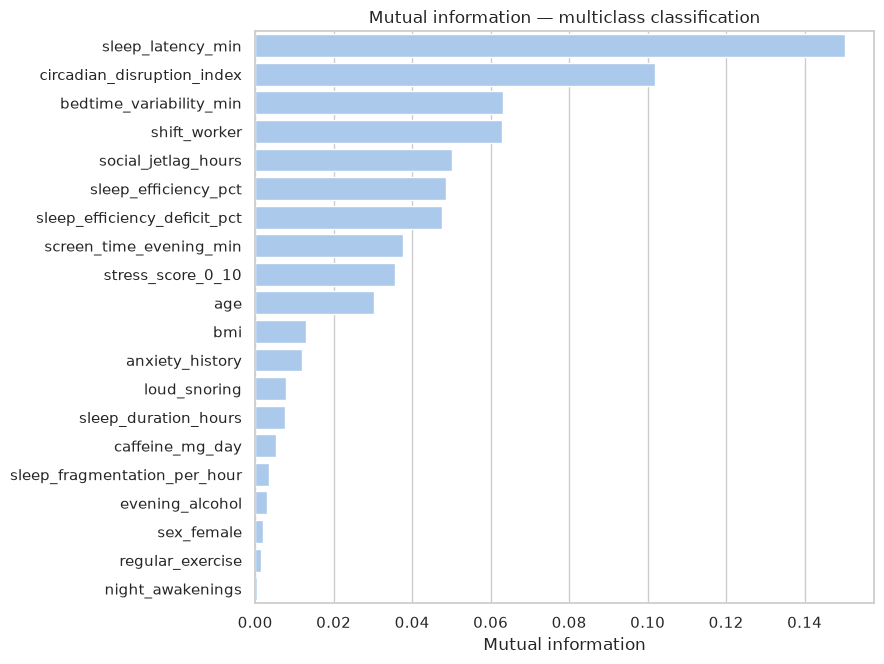

In [12]:
X_train = train_eng[FEATURE_COLUMNS]
y_train = train_eng[TARGET_COLUMN]

discrete_mask = np.array([feature in CATEGORICAL_COLUMNS for feature in FEATURE_COLUMNS])
mi_values = mutual_info_classif(
    X_train,
    y_train,
    discrete_features=discrete_mask,
    random_state=RANDOM_STATE,
)

mutual_information = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "mutual_information": mi_values,
}).sort_values("mutual_information", ascending=False).reset_index(drop=True)

positive_mi = mutual_information.loc[mutual_information["mutual_information"] > 0, "mutual_information"]
mi_threshold = positive_mi.quantile(0.75) if len(positive_mi) else np.inf
mutual_information["top_quartile_positive_mi"] = (
    mutual_information["mutual_information"] >= mi_threshold
)

display(mutual_information.round(4))
mutual_information.to_csv(TABLES_DIR / "mutual_information.csv", index=False)
plot_horizontal_ranking(
    mutual_information,
    "mutual_information",
    "feature",
    "Mutual information — multiclass classification",
    "Mutual information",
    FIGURES_DIR / "04_mutual_information.png",
)

# Part V — Embedded multiclass selection

## 12. L1-regularized multinomial logistic regression

The model learns one coefficient vector per class. A predictor is considered retained if it has a nonzero coefficient for **at least one class**.

Regularization strength is selected by stratified cross-validation on the training partition. Standardization is inside the pipeline.

Best C: 0.07196856730011521
Best training-CV balanced accuracy: 0.492


,feature,max_abs_coefficient,embedded_selected
0,sleep_latency_min,0.5873,True
1,circadian_disruption_index,0.4352,True
2,stress_score_0_10,0.3371,True
3,shift_worker,0.2897,True
4,night_awakenings,0.2514,True
5,age,0.2027,True
6,loud_snoring,0.1846,True
7,bmi,0.1118,True
8,sleep_efficiency_pct,0.1006,True
9,sleep_efficiency_deficit_pct,0.1006,True


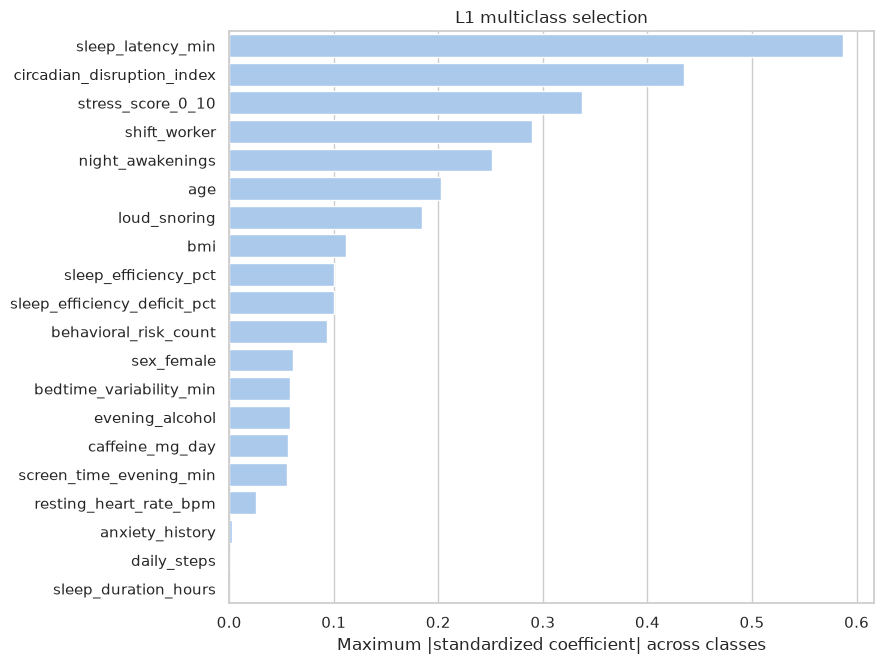

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

multiclass_l1_pipeline = Pipeline([
    ("scale", StandardScaler()),
    (
        "model",
        LogisticRegression(
            solver="saga",
            l1_ratio=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
    ),
])

multiclass_l1_search = GridSearchCV(
    multiclass_l1_pipeline,
    param_grid={"model__C": np.logspace(-2, 1, 8)},
    scoring="balanced_accuracy",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
multiclass_l1_search.fit(X_train, y_train)

best_model = multiclass_l1_search.best_estimator_.named_steps["model"]
coef_matrix = pd.DataFrame(
    best_model.coef_,
    index=best_model.classes_,
    columns=FEATURE_COLUMNS,
)
max_abs_coef = coef_matrix.abs().max(axis=0)

embedded_table = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "max_abs_coefficient": max_abs_coef.reindex(FEATURE_COLUMNS).to_numpy(),
})
embedded_table["embedded_selected"] = embedded_table["max_abs_coefficient"] > 1e-8
embedded_table = embedded_table.sort_values("max_abs_coefficient", ascending=False).reset_index(drop=True)

print("Best C:", multiclass_l1_search.best_params_["model__C"])
print("Best training-CV balanced accuracy:", round(multiclass_l1_search.best_score_, 3))
display(embedded_table.round(4))
embedded_table.to_csv(TABLES_DIR / "l1_multiclass_coefficient_summary.csv", index=False)
coef_matrix.to_csv(TABLES_DIR / "l1_multiclass_coefficients_by_class.csv")

plot_horizontal_ranking(
    embedded_table,
    "max_abs_coefficient",
    "feature",
    "L1 multiclass selection",
    "Maximum |standardized coefficient| across classes",
    FIGURES_DIR / "05_l1_multiclass_coefficient_magnitude.png",
)

## 13. Class-specific coefficient map

A global magnitude ranking can hide *which* class is associated with a feature. The heatmap preserves that structure.

Coefficients should be interpreted as model parameters under regularization, not as causal effects.

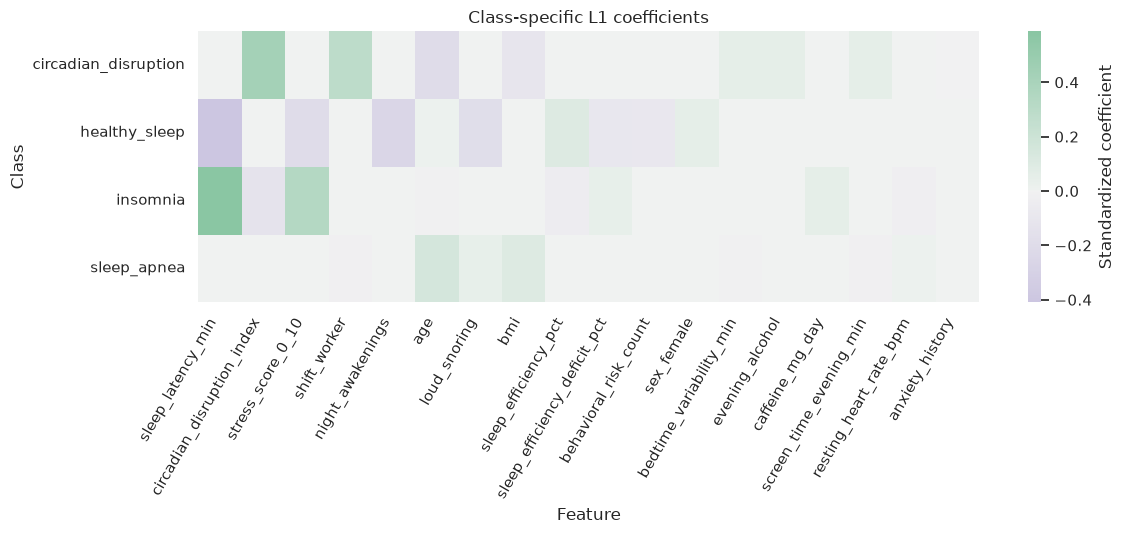

In [14]:
selected_for_heatmap = embedded_table.head(18)["feature"].tolist()
plt.figure(figsize=(12, 5.5))
sns.heatmap(
    coef_matrix[selected_for_heatmap],
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    annot=False,
    cbar_kws={"label": "Standardized coefficient"},
)
plt.title("Class-specific L1 coefficients")
plt.xlabel("Feature")
plt.ylabel("Class")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_l1_coefficients_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

# Part VI — Consensus candidate features

## 14. Combine complementary evidence

The vote system mirrors Task 1 but keeps the multiclass-aware methods:

- omnibus statistical filter;
- top-quartile positive mutual information;
- nonzero L1 coefficient in at least one class.

At least two votes are required for the illustrative consensus set.

In [15]:
filter_selected = set(
    numerical_filter.loc[numerical_filter["filter_selected"], "feature"]
).union(
    categorical_filter.loc[categorical_filter["filter_selected"], "feature"]
)
mi_selected = set(
    mutual_information.loc[mutual_information["top_quartile_positive_mi"], "feature"]
)
embedded_selected = set(
    embedded_table.loc[embedded_table["embedded_selected"], "feature"]
)

selection_summary = pd.DataFrame({"feature": FEATURE_COLUMNS})
selection_summary["filter_selected"] = selection_summary["feature"].isin(filter_selected)
selection_summary["mi_top_quartile"] = selection_summary["feature"].isin(mi_selected)
selection_summary["l1_selected"] = selection_summary["feature"].isin(embedded_selected)
selection_summary["selection_votes"] = selection_summary[
    ["filter_selected", "mi_top_quartile", "l1_selected"]
].sum(axis=1)
selection_summary["consensus_selected"] = selection_summary["selection_votes"] >= 2
selection_summary = selection_summary.sort_values(
    ["selection_votes", "feature"], ascending=[False, True]
).reset_index(drop=True)

CONSENSUS_FEATURES = selection_summary.loc[
    selection_summary["consensus_selected"], "feature"
].tolist()

display(selection_summary)
print(f"All candidate predictors: {len(FEATURE_COLUMNS)}")
print(f"Consensus candidate predictors: {len(CONSENSUS_FEATURES)}")
print(CONSENSUS_FEATURES)
selection_summary.to_csv(TABLES_DIR / "feature_selection_summary.csv", index=False)

,feature,filter_selected,mi_top_quartile,l1_selected,selection_votes,consensus_selected
0,bedtime_variability_min,True,True,True,3,True
1,circadian_disruption_index,True,True,True,3,True
2,shift_worker,True,True,True,3,True
3,sleep_latency_min,True,True,True,3,True
4,age,True,False,True,2,True
5,anxiety_history,True,False,True,2,True
6,behavioral_risk_count,True,False,True,2,True
7,bmi,True,False,True,2,True
8,loud_snoring,True,False,True,2,True
9,night_awakenings,True,False,True,2,True


All candidate predictors: 26
Consensus candidate predictors: 15
['bedtime_variability_min', 'circadian_disruption_index', 'shift_worker', 'sleep_latency_min', 'age', 'anxiety_history', 'behavioral_risk_count', 'bmi', 'loud_snoring', 'night_awakenings', 'screen_time_evening_min', 'sleep_efficiency_deficit_pct', 'sleep_efficiency_pct', 'social_jetlag_hours', 'stress_score_0_10']


## 15. Export the feature manifest

In [16]:
manifest = {
    "dataset": "synthetic_sleep_profiles",
    "task_type": "multiclass_classification",
    "classes": TARGET_CLASSES,
    "random_state": RANDOM_STATE,
    "train_size": len(train_eng),
    "test_size": len(test_eng),
    "original_numerical_features": ORIGINAL_NUMERICAL,
    "engineered_numerical_features": ENGINEERED_NUMERICAL,
    "categorical_features": CATEGORICAL_COLUMNS,
    "all_candidate_features": FEATURE_COLUMNS,
    "filter_selected_features": sorted(filter_selected),
    "mutual_information_top_quartile_features": sorted(mi_selected),
    "l1_selected_features": sorted(embedded_selected),
    "consensus_features": CONSENSUS_FEATURES,
    "note": (
        "Supervised selection was learned on the training partition only. "
        "Formal model benchmarking should refit selection inside each training fold."
    ),
}
with (RESULTS_DIR / "feature_selection_manifest.json").open("w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

print("Feature manifest exported.")

Feature manifest exported.


# Final interpretation

Multiclass feature selection should preserve the fact that there are several distinct groups. A feature can be useful because it separates only one profile, because it changes gradually across profiles, or because it interacts with other predictors.

The workflow therefore combines **omnibus statistics**, **nonlinear dependence**, and **class-specific regularized coefficients**. The resulting feature sets are hypotheses to test during model development, not final truths extracted from the dataset.